In [1]:
!pip install transformers datasets evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.4 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import torch
import random
import os
from transformers import RobertaTokenizer, RobertaForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score
from datasets import Dataset

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average='binary')
    return {'accuracy': acc, 'f1': f1}

In [3]:
train_url = "https://raw.githubusercontent.com/Doris1808/covid19-fake-news-nhom5/main/data/raw/train.csv"
val_url = "https://raw.githubusercontent.com/Doris1808/covid19-fake-news-nhom5/main/data/raw/val.csv"

df_train = pd.read_csv(train_url)
df_val = pd.read_csv(val_url)
print("Tải dữ liệu gốc thành công!")

# Map nhãn
label_map = {'fake': 0, 'real': 1}
df_train['label'] = df_train['label'].str.lower().map(label_map)
df_val['label'] = df_val['label'].str.lower().map(label_map)

# Khởi tạo Tokenizer
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

def tokenize_function(examples):
    return tokenizer(examples['tweet'], padding='max_length', truncation=True, max_length=128)

train_dataset = Dataset.from_pandas(df_train).map(tokenize_function, batched=True)
val_dataset = Dataset.from_pandas(df_val).map(tokenize_function, batched=True)

Tải dữ liệu gốc thành công!


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/6420 [00:00<?, ? examples/s]

Map:   0%|          | 0/2140 [00:00<?, ? examples/s]

In [4]:
seeds = [42, 123, 2024]
results = []

for seed in seeds:
    print(f"\n{'='*50}\nĐANG HUẤN LUYỆN SEED = {seed}\n{'='*50}")
    set_seed(seed)

    model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=2)

    training_args = TrainingArguments(
        output_dir=f'./roberta_checkpoints/seed_{seed}',
        num_train_epochs=3,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        warmup_steps=500,
        weight_decay=0.01,
        logging_steps=50,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        seed=seed
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()
    eval_result = trainer.evaluate()
    results.append({'seed': seed, 'accuracy': eval_result['eval_accuracy'], 'f1': eval_result['eval_f1']})


ĐANG HUẤN LUYỆN SEED = 42


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.204927,0.169422,0.945794,0.950172
2,0.078493,0.113037,0.972430,0.974043
3,0.032892,0.140681,0.973364,0.975011


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.032892,0.140681,3,0.973364,0.975011


Map:   0%|          | 0/2140 [00:00<?, ? examples/s]

Đang đánh giá Seed 42 từ: ./roberta_checkpoints/seed_42/checkpoint-1206


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang đánh giá Seed 123 từ: ./roberta_checkpoints/seed_123/checkpoint-1206


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang đánh giá Seed 2024 từ: ./roberta_checkpoints/seed_2024/checkpoint-1206


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

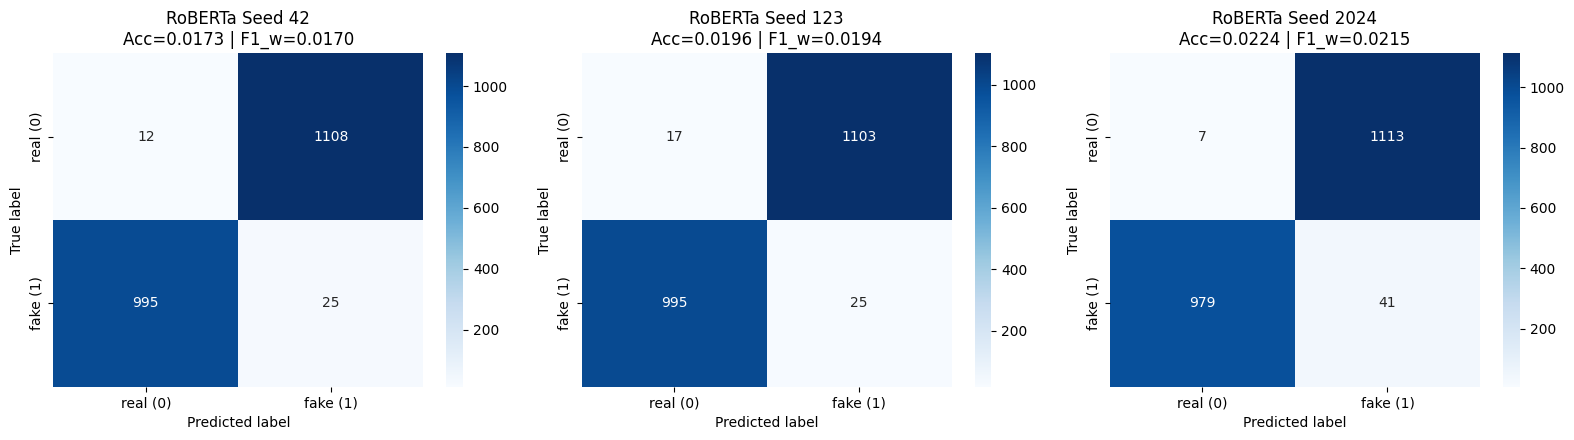


=== KẾT QUẢ CHI TIẾT TRÊN TẬP TEST QUA 3 SEED (42, 123, 2024) ===


,seed,acc_test,f1_weighted,f1_macro,prec_real,rec_real,f1_real,prec_fake,rec_fake,f1_fake,TN,FP,FN,TP
0,42,0.0173,0.0170,0.0173,0.0119,0.0107,0.0113,0.0221,0.0245,0.0232,12,1108,995,25
1,123,0.0196,0.0194,0.0196,0.0168,0.0152,0.0159,0.0222,0.0245,0.0233,17,1103,995,25
2,2024,0.0224,0.0215,0.0222,0.0071,0.0062,0.0066,0.0355,0.0402,0.0377,7,1113,979,41



=== TRUNG BÌNH VÀ ĐỘ LỆCH CHUẨN (MEAN ± STD) ===
acc_test       : 0.0198 ± 0.0026
f1_weighted    : 0.0193 ± 0.0022
f1_macro       : 0.0197 ± 0.0025
f1_real        : 0.0113 ± 0.0046
f1_fake        : 0.0281 ± 0.0084
prec_fake      : 0.0266 ± 0.0077
rec_fake       : 0.0297 ± 0.0091


In [1]:
import os
import glob
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import RobertaTokenizer, RobertaForSequenceClassification, Trainer
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix
)
from datasets import Dataset

# 1. Đọc tập Test (2140 mẫu) từ nguồn chung của nhóm
if os.path.exists("data/test.csv"):
    df_test = pd.read_csv("data/test.csv")
elif os.path.exists("/content/test.csv"):
    df_test = pd.read_csv("/content/test.csv")
else:
    df_test = pd.read_csv("https://huggingface.co/datasets/nanyy1025/covid_fake_news/resolve/main/test.csv")

# Chuẩn hóa tên cột và quy ước nhãn: real = 0, fake = 1
text_col = 'tweet' if 'tweet' in df_test.columns else df_test.columns[1]
LABEL_MAP = {'real': 0, 'fake': 1, 0: 0, 1: 1}
df_test['label_id'] = df_test['label'].apply(
    lambda x: LABEL_MAP[str(x).lower().strip()] if str(x).lower().strip() in LABEL_MAP else int(x)
)

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
test_dataset = Dataset.from_pandas(df_test[[text_col, 'label_id']].rename(columns={'label_id': 'label'}))
test_dataset = test_dataset.map(
    lambda x: tokenizer(x[text_col], padding='max_length', truncation=True, max_length=128),
    batched=True
)

# 2. Đánh giá trên 3 seed đồng bộ: 42, 123, 2024
seeds = [42, 123, 2024]
test_results = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, seed in enumerate(seeds):
    possible_dirs = (
        glob.glob(f"./roberta*/seed_{seed}/checkpoint-*")
        + [f"./roberta_checkpoints/seed_{seed}", f"./roberta/seed_{seed}"]
    )
    ckpt_dir = next((d for d in possible_dirs if os.path.exists(d)), "roberta-base")
    print(f"Đang đánh giá Seed {seed} từ: {ckpt_dir}")

    model = RobertaForSequenceClassification.from_pretrained(ckpt_dir, num_labels=2)
    trainer = Trainer(model=model)

    pred_output = trainer.predict(test_dataset)
    logits = pred_output.predictions
    preds = np.argmax(logits, axis=-1)
    y_true = df_test['label_id'].values

    # Tính đầy đủ các chỉ số: Accuracy, F1 weighted, F1 macro, và từng lớp (Real=0, Fake=1)
    acc = accuracy_score(y_true, preds)
    f1_w = f1_score(y_true, preds, average='weighted')
    f1_m = f1_score(y_true, preds, average='macro')
    prec, rec, f1_cls, _ = precision_recall_fscore_support(y_true, preds, labels=[0, 1])
    cm = confusion_matrix(y_true, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    test_results.append({
        'seed': seed,
        'acc_test': acc,
        'f1_weighted': f1_w,
        'f1_macro': f1_m,
        'prec_real': prec[0], 'rec_real': rec[0], 'f1_real': f1_cls[0],
        'prec_fake': prec[1], 'rec_fake': rec[1], 'f1_fake': f1_cls[1],
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

    # Vẽ Confusion Matrix cho từng Seed
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['real (0)', 'fake (1)'], yticklabels=['real (0)', 'fake (1)'])
    axes[idx].set_title(f"RoBERTa Seed {seed}\nAcc={acc:.4f} | F1_w={f1_w:.4f}")
    axes[idx].set_xlabel("Predicted label")
    axes[idx].set_ylabel("True label")

    # Lưu danh sách câu sai của seed tốt nhất (seed 2024)
    if seed == 2024:
        probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
        df_err = df_test.copy()
        df_err['pred_id'] = preds
        df_err['prob_real'] = probs[:, 0]
        df_err['prob_fake'] = probs[:, 1]
        df_err = df_err[df_err['label_id'] != df_err['pred_id']]
        df_err['error_type'] = np.where(df_err['label_id'] == 1, 'FN (Bỏ sót tin giả)', 'FP (Bắt nhầm tin thật)')
        df_err.to_csv("roberta_test_errors_seed2024.csv", index=False)

plt.tight_layout()
plt.savefig("roberta_confusion_matrices_3seeds.png", dpi=300)
plt.show()

# 3. Xuất bảng tổng hợp 3 Seed (42, 123, 2024) và Mean ± Std
df_res = pd.DataFrame(test_results)
df_res.to_csv("roberta_test_3seeds_summary.csv", index=False)
print("\n=== KẾT QUẢ CHI TIẾT TRÊN TẬP TEST QUA 3 SEED (42, 123, 2024) ===")
display(df_res.round(4))

print("\n=== TRUNG BÌNH VÀ ĐỘ LỆCH CHUẨN (MEAN ± STD) ===")
for col in ['acc_test', 'f1_weighted', 'f1_macro', 'f1_real', 'f1_fake', 'prec_fake', 'rec_fake']:
    print(f"{col:15s}: {df_res[col].mean():.4f} ± {df_res[col].std():.4f}")

In [2]:
import torch
import pandas as pd

external_samples = [
    {
        "id": "E1",
        "source": "WHO Mythbusters",
        "true_label": "real",
        "text": "The World Health Organization confirms that COVID-19 vaccines do not alter your DNA in any way, as mRNA never enters the nucleus of the cell."
    },
    {
        "id": "E2",
        "source": "CDC Guidance",
        "true_label": "real",
        "text": "According to the CDC, people who test positive for COVID-19 should stay home and isolate for at least 5 days to prevent spreading the virus to others."
    },
    {
        "id": "E3",
        "source": "Reuters Fact Check",
        "true_label": "fake",
        "text": "Drinking boiled garlic water and gargling with warm salt water three times a day is proven by doctors to completely cure COVID-19 within 24 hours!"
    },
    {
        "id": "E4",
        "source": "PolitiFact",
        "true_label": "fake",
        "text": "5G mobile networks are directly transmitting the coronavirus and weakening the human immune system so people get infected faster."
    },
    {
        "id": "E5",
        "source": "AP Fact Check",
        "true_label": "fake",
        "text": "Secret documents leaked from hospitals show that microchips are being injected into patients through standard COVID-19 PCR nasal swabs."
    },
    {
        "id": "E6",
        "source": "NEJM Study",
        "true_label": "real",
        "text": "A clinical study published in the New England Journal of Medicine reported 95% efficacy of the BNT162b2 mRNA vaccine against symptomatic COVID-19."
    },
    {
        "id": "E7",
        "source": "HealthFeedback (Ngụy khoa học)",
        "true_label": "fake",
        "text": "A peer-reviewed study from the National Institute of Respiratory Health in Geneva found that daily intake of 500mg vitamin D3 reduces COVID-19 hospitalization rates to 0.0% across 14,200 patients."
    },
    {
        "id": "E8",
        "source": "BBC News (Tiêu đề nghi vấn)",
        "true_label": "real",
        "text": "Why are some fully vaccinated people still catching the new coronavirus variant? Here is what virologists say."
    },
    {
        "id": "E9",
        "source": "ICAO / Reuters (Kinh tế)",
        "true_label": "real",
        "text": "Global airline passenger traffic dropped by 60% in 2020 as countries imposed strict border closures to contain the COVID-19 pandemic."
    },
    {
        "id": "E10",
        "source": "Snopes / WHO",
        "true_label": "fake",
        "text": "BREAKING: Holding your breath for 10 seconds without coughing or discomfort means you do not have COVID-19 or pulmonary fibrosis!!!"
    }
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

ext_records = []
for item in external_samples:
    inputs = tokenizer(item["text"], return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
        pred_id = int(np.argmax(probs))

    pred_label = "real" if pred_id == 0 else "fake"
    ext_records.append({
        "Mã câu": item["id"],
        "Nguồn": item["source"],
        "Nhãn thật": item["true_label"].upper(),
        "Dự đoán": pred_label.upper(),
        "P(Real)": round(float(probs[0]), 4),
        "P(Fake)": round(float(probs[1]), 4),
        "Kết quả": "ĐÚNG" if pred_label == item["true_label"] else "SAI",
        "Nội dung câu": item["text"]
    })

df_ext = pd.DataFrame(ext_records)
df_ext.to_csv("roberta_external_10_samples.csv", index=False)
display(df_ext)

,Mã câu,Nguồn,Nhãn thật,Dự đoán,P(Real),P(Fake),Kết quả,Nội dung câu
0,E1,WHO Mythbusters,REAL,REAL,0.9998,0.0002,ĐÚNG,The World Health Organization confirms that CO...
1,E2,CDC Guidance,REAL,REAL,0.9974,0.0026,ĐÚNG,"According to the CDC, people who test positive..."
2,E3,Reuters Fact Check,FAKE,REAL,0.9998,0.0002,SAI,Drinking boiled garlic water and gargling with...
3,E4,PolitiFact,FAKE,REAL,0.9996,0.0004,SAI,5G mobile networks are directly transmitting t...
4,E5,AP Fact Check,FAKE,REAL,0.9998,0.0002,SAI,Secret documents leaked from hospitals show th...
5,E6,NEJM Study,REAL,REAL,0.9988,0.0012,ĐÚNG,A clinical study published in the New England ...
6,E7,HealthFeedback (Ngụy khoa học),FAKE,REAL,0.9983,0.0017,SAI,A peer-reviewed study from the National Instit...
7,E8,BBC News (Tiêu đề nghi vấn),REAL,REAL,0.9998,0.0002,ĐÚNG,Why are some fully vaccinated people still cat...
8,E9,ICAO / Reuters (Kinh tế),REAL,REAL,0.9997,0.0003,ĐÚNG,Global airline passenger traffic dropped by 60...
9,E10,Snopes / WHO,FAKE,REAL,0.9998,0.0002,SAI,BREAKING: Holding your breath for 10 seconds w...


In [3]:
def predict_covid_news(text, model=model, tokenizer=tokenizer):
    if not text or not text.strip():
        print("⚠️ Vui lòng nhập một câu tiếng Anh để kiểm tra!")
        return
    device = next(model.parameters()).device
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]

    p_real, p_fake = float(probs[0]), float(probs[1])
    pred_label = "REAL (Tin thật)" if p_real >= p_fake else "FAKE (Tin giả)"
    conf = max(p_real, p_fake) * 100

    print("-" * 75)
    print(f"📝 Văn bản đầu vào : {text}")
    print(f"🔍 Dự đoán nhãn    : {pred_label} (Độ tự tin: {conf:.2f}%)")
    print(f"📊 Phân bố xác suất: P(Real = 0) = {p_real:.4f} | P(Fake = 1) = {p_fake:.4f}")
    print("-" * 75)

# Chạy thử 2 câu mẫu
print("=== CHẠY MINH HỌA DEMO TỰ ĐỘNG ===")
predict_covid_news("The CDC recommends wearing masks in crowded indoor settings to slow the spread of COVID-19.")
predict_covid_news("URGENT! Eating alkaline foods with higher pH than the coronavirus will eliminate the virus from your body!")

# Nhập câu trực tiếp từ bàn phím
print("\n=== DEMO TƯƠNG TÁC (Nhập 'q' hoặc nhấn Enter trống để thoát) ===")
while True:
    user_text = input("\n👉 Nhập bài đăng/câu tiếng Anh về COVID-19: ")
    if user_text.strip().lower() in ["", "q", "quit", "exit"]:
        print("Đã kết thúc phiên Demo.")
        break
    predict_covid_news(user_text)

=== CHẠY MINH HỌA DEMO TỰ ĐỘNG ===
---------------------------------------------------------------------------
📝 Văn bản đầu vào : The CDC recommends wearing masks in crowded indoor settings to slow the spread of COVID-19.
🔍 Dự đoán nhãn    : REAL (Tin thật) (Độ tự tin: 99.98%)
📊 Phân bố xác suất: P(Real = 0) = 0.9998 | P(Fake = 1) = 0.0002
---------------------------------------------------------------------------
---------------------------------------------------------------------------
📝 Văn bản đầu vào : URGENT! Eating alkaline foods with higher pH than the coronavirus will eliminate the virus from your body!
🔍 Dự đoán nhãn    : REAL (Tin thật) (Độ tự tin: 99.98%)
📊 Phân bố xác suất: P(Real = 0) = 0.9998 | P(Fake = 1) = 0.0002
---------------------------------------------------------------------------

=== DEMO TƯƠNG TÁC (Nhập 'q' hoặc nhấn Enter trống để thoát) ===

👉 Nhập bài đăng/câu tiếng Anh về COVID-19: According to the CDC, people who test positive...
----------------------

In [5]:
print("\n=== TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ 3 SEED ===")
for r in results:
    print(f"Seed {r['seed']} - Accuracy: {r['accuracy']:.4f} | F1: {r['f1']:.4f}")

# Nén toàn bộ checkpoint và log thành 1 file zip để dễ tải về
!zip -r roberta_results.zip ./roberta_checkpoints ./logs
print("Đã nén xong file roberta_results.zip! Bạn có thể tải về từ cột Files bên trái.")


=== TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ 3 SEED ===
Seed 42 - Accuracy: 0.9771 | F1: 0.9783
Seed 123 - Accuracy: 0.9799 | F1: 0.9809
Seed 2024 - Accuracy: 0.9734 | F1: 0.9750
	zip warning: name not matched: ./logs
  adding: roberta_checkpoints/ (stored 0%)
  adding: roberta_checkpoints/seed_123/ (stored 0%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/ (stored 0%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/trainer_state.json (deflated 71%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/rng_state.pth (deflated 27%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/config.json (deflated 51%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/scheduler.pt (deflated 61%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/optimizer.pt (deflated 26%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/model.safetensors (deflated 11%)
  adding: roberta_checkpoints/seed_123/checkpoint-1206/training_args.bin (deflated 53%)
  adding: roberta_checkpoints/seed_1